# 2. Naive Bayes mit TF-IDF (Klassischer Algorithmus)

In diesem Notebook trainieren wir ein Naive Bayes Modell mit TF-IDF Features als Baseline.


In [7]:
# Import der benötigten Bibliotheken
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer  # TF-IDF Vektorisierung
from sklearn.naive_bayes import MultinomialNB  # Naive Bayes Klassifikator
from sklearn.pipeline import Pipeline  # Pipeline für Feature-Extraktion + Klassifikation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib  # Zum Speichern des trainierten Modells
import warnings
warnings.filterwarnings('ignore')  


current_dir = Path().resolve()
if current_dir.name == 'src':
    BASE_DIR = current_dir.parent
else:
    BASE_DIR = current_dir

sys.path.insert(0, str(BASE_DIR / "src"))

from utils_imdb import read_imdb_split, basic_clean

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print(f"BASE_DIR: {BASE_DIR}")
print(f"DATA_ROOT wird sein: {BASE_DIR / 'data' / 'aclImdb'}")


BASE_DIR: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining
DATA_ROOT wird sein: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining\data\aclImdb


## 2.1 Daten laden und vorbereiten


In [8]:
# Pfade definieren
DATA_ROOT = BASE_DIR / "data" / "aclImdb"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  

# Debug: Prüfe welche Dateien vorhanden sind
import glob

print("=== Debug: Prüfe verfügbare Dateien ===")
print(f"DATA_ROOT: {DATA_ROOT}")
print(f"Existiert DATA_ROOT: {DATA_ROOT.exists()}")

# Konvertiere Path-Objekt zu String für glob
data_root_str = str(DATA_ROOT)
train_pos_files = glob.glob(os.path.join(data_root_str, "train", "pos", "*.txt"))
train_neg_files = glob.glob(os.path.join(data_root_str, "train", "neg", "*.txt"))
test_pos_files = glob.glob(os.path.join(data_root_str, "test", "pos", "*.txt"))
test_neg_files = glob.glob(os.path.join(data_root_str, "test", "neg", "*.txt"))

print(f"Train/pos: {len(train_pos_files)} Dateien")
print(f"Train/neg: {len(train_neg_files)} Dateien")
print(f"Test/pos: {len(test_pos_files)} Dateien")
print(f"Test/neg: {len(test_neg_files)} Dateien")

if len(train_pos_files) == 0 and len(train_neg_files) == 0:
    print("\n WARNUNG: Keine Trainingsdaten gefunden!")
    print(f"   Erwarteter Pfad: {DATA_ROOT / 'train'}")

print("\n" + "="*60)
print("Lade Daten...")
MAX_DOCS_PER_CLASS = None

# Trainings- und Testdaten laden
train = read_imdb_split(DATA_ROOT / "train", max_docs_per_class=MAX_DOCS_PER_CLASS)
test = read_imdb_split(DATA_ROOT / "test", max_docs_per_class=MAX_DOCS_PER_CLASS)

# Prüfe ob Daten geladen wurden
if len(train) == 0:
    raise ValueError(" FEHLER: Keine Trainingsdaten geladen! ")
if len(test) == 0:
    raise ValueError(" FEHLER: Keine Testdaten geladen!")

# Datenvorverarbeitung:
# - Texte bereinigen (Kleinschreibung, Sonderzeichen entfernen, etc.)
# - Labels extrahieren
X_train = train["text"].apply(basic_clean)
X_test = test["text"].apply(basic_clean)
y_train, y_test = train["label"], test["label"]

# Datensatz-Informationen ausgeben
print(f"\nTrainingsdaten: {len(X_train)} Reviews")
print(f"Testdaten: {len(X_test)} Reviews")
print(f"\nLabel-Verteilung in Trainingsdaten:")
print(y_train.value_counts())
print(f"\nLabel-Verteilung in Testdaten:")
print(y_test.value_counts())


=== Debug: Prüfe verfügbare Dateien ===
DATA_ROOT: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining\data\aclImdb
Existiert DATA_ROOT: True
Train/pos: 12500 Dateien
Train/neg: 12500 Dateien
Test/pos: 12500 Dateien
Test/neg: 12500 Dateien

Lade Daten...



KeyboardInterrupt



## 2.2 Modell definieren und trainieren


In [ ]:
# Prüfe ob Trainingsdaten vorhanden sind
if len(X_train) == 0:
    raise ValueError(" FEHLER: Keine Trainingsdaten vorhanden! Das Modell kann nicht trainiert werden.")

# Pipeline erstellen: TF-IDF Vektorisierung + Naive Bayes Klassifikator
# Eine Pipeline kombiniert mehrere Schritte (Feature-Extraktion + Klassifikation)
clf = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50_000,  # Maximale Anzahl der wichtigsten Features 
        ngram_range=(1, 2),  # Unigramme  und Bigramme 
        min_df=2,  # Mind. Dokumentenfrequenz: Wort muss in mind. 2 Dokumenten vorkommen
        strip_accents="unicode",  # Akzente entfernen (z.B. é -> e)
    )),
    ("nb", MultinomialNB(alpha=0.5)),  # Naive Bayes mit Laplace-Glättung (alpha=0.5)
])

print("Trainiere Modell...")
print(f"Anzahl Trainingsdaten: {len(X_train)}")
print(f"Anzahl Testdaten: {len(X_test)}")

# Modell auf Trainingsdaten trainieren
clf.fit(X_train, y_train)
print("Training abgeschlossen!")


Trainiere Modell...
Anzahl Trainingsdaten: 25000
Anzahl Testdaten: 25000
Training abgeschlossen!


## 2.3 Evaluation


In [ ]:
# Vorhersagen auf Testdaten machen
# Die Pipeline wendet automatisch TF-IDF Transformation an und macht dann Vorhersagen
pred = clf.predict(X_test)

# Metriken berechnen und ausgeben
accuracy = accuracy_score(y_test, pred)
print(f"Test-Genauigkeit (Accuracy): {accuracy:.4f}")
print("\nKlassifikationsbericht (Precision, Recall, F1-Score):")
print(classification_report(y_test, pred, digits=4))
print("\nKonfusionsmatrix:")
# Konfusionsmatrix zeigt: True Negatives, False Positives, False Negatives, True Positives
cm = confusion_matrix(y_test, pred)
print(cm)


Test-Genauigkeit (Accuracy): 0.8705

Klassifikationsbericht (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

           0     0.8586    0.8870    0.8726     12500
           1     0.8832    0.8539    0.8683     12500

    accuracy                         0.8705     25000
   macro avg     0.8709    0.8705    0.8704     25000
weighted avg     0.8709    0.8705    0.8704     25000


Konfusionsmatrix:
[[11088  1412]
 [ 1826 10674]]


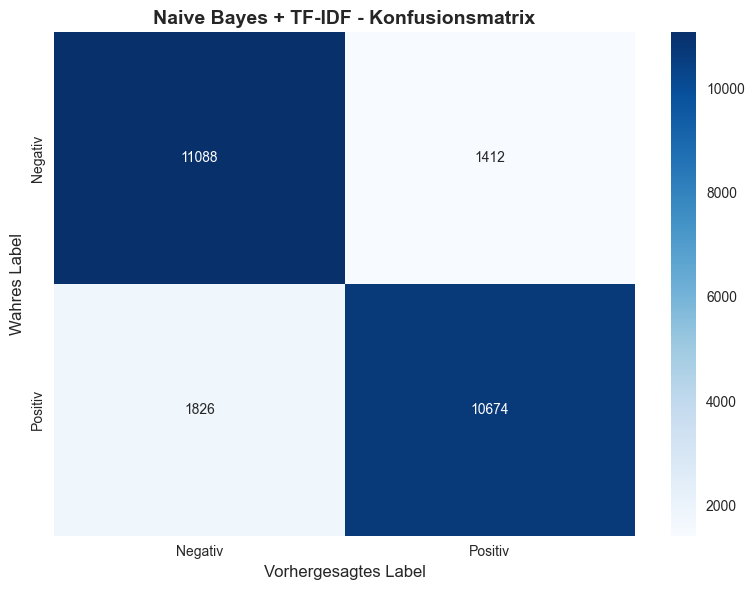

In [ ]:
# Konfusionsmatrix visualisieren
# Die Heatmap zeigt, wie viele Reviews korrekt/inkorrekt klassifiziert wurden
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Negativ', 'Positiv'],
            yticklabels=['Negativ', 'Positiv'])
ax.set_title('Naive Bayes + TF-IDF - Konfusionsmatrix', fontsize=14, fontweight='bold')
ax.set_ylabel('Wahres Label', fontsize=12)
ax.set_xlabel('Vorhergesagtes Label', fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_nb.png", dpi=300, bbox_inches='tight')
plt.show()


## 2.4 Modell und Predictions speichern


In [ ]:
# Modell speichern für spätere Verwendung
models_dir = OUTPUT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True) 
model_path = models_dir / "nb_tfidf_imdb.joblib"
joblib.dump(clf, model_path)  # Gesamte Pipeline (TF-IDF + Naive Bayes) speichern
print(f"Modell gespeichert: {model_path}")

# Vorhersagen speichern für spätere Analyse und Vergleich
preds_path = OUTPUT_DIR / "preds_nb.csv"
pd.DataFrame({
    "text": X_test,      # Original-Text
    "y_true": y_test,    # Wahre Labels
    "y_pred": pred       # Vorhergesagte Labels
}).to_csv(preds_path, index=False, encoding="utf-8")
print(f"Vorhersagen gespeichert: {preds_path}")


Modell gespeichert: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining\outputs\models\nb_tfidf_imdb.joblib
Vorhersagen gespeichert: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining\outputs\preds_nb.csv
